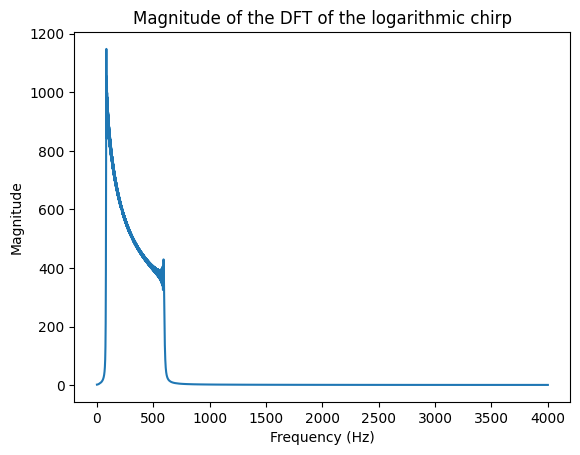

/var/folders/hy/kl7wj11525l7dzlfzm123s_c0000gn/T/ipykernel_1446/2848182950.py:19: UserWarning: amplitude_to_db was called on complex input so phase information will be discarded. To suppress this warning, call amplitude_to_db(np.abs(S)) instead.
  librosa.display.specshow(librosa.amplitude_to_db(X2, ref=np.max), sr=sr, x_axis='time', y_axis='log')


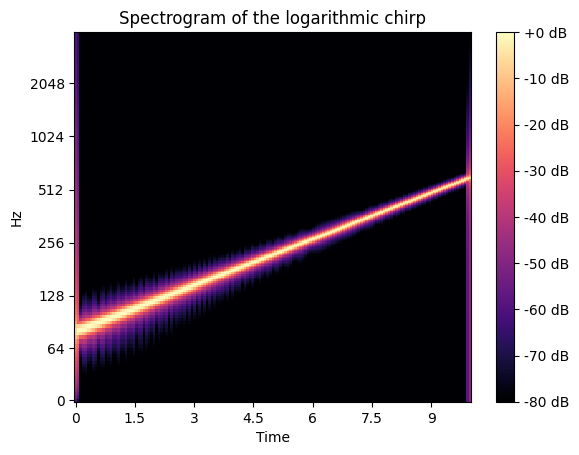

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fftpack import fft
import librosa

x, sr = librosa.load('logarithmic_chirp.wav', sr=None)
f = np.fft.rfftfreq(len(x), 1/sr)
X = np.fft.rfft(x)

plt.figure()
plt.plot(f, np.abs(X))
plt.title('Magnitude of the DFT of the logarithmic chirp')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.show()

X2 = librosa.stft(x, n_fft=2048, hop_length=512)
plt.figure()
librosa.display.specshow(librosa.amplitude_to_db(X2, ref=np.max), sr=sr, x_axis='time', y_axis='log')
plt.colorbar(format='%+2.0f dB')
plt.title('Spectrogram of the logarithmic chirp')
plt.show()


In [ ]:
import soundfile as sf

fs = 2000
t = np.arange(0, 2, 1/fs)

x1 = np.sin(2*np.pi*500*t + 200*np.cos(2*np.pi*t))
x2 = np.sin(2*np.pi*590*t + 200*np.cos(2*np.pi*t))

x = x1+x2

sf.write('resolution.wav', x, fs)

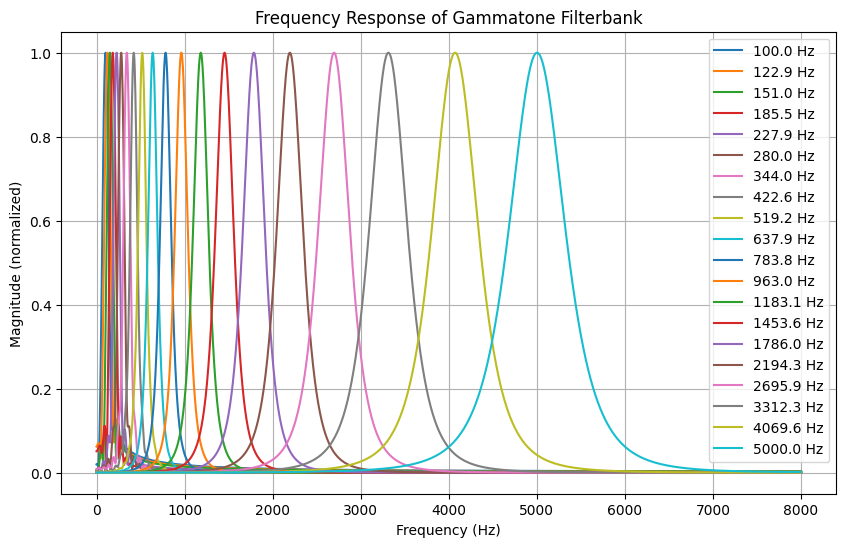

In [3]:
def gammatone_freq_response(fs=16000, num_filters=20, low_freq=100, high_freq=5000, order=4, n_fft=4096):
    """
    Compute and plot the frequency response of a Gammatone filterbank.

    Parameters:
    - fs (int): Sampling frequency in Hz.
    - num_filters (int): Number of filters in the filterbank.
    - low_freq (float): Lowest center frequency of the filterbank.
    - high_freq (float): Highest center frequency of the filterbank.
    - order (int): Order of the Gammatone filter (typically 4).
    - n_fft (int): Number of FFT points for frequency response.
    """

    # Generate center frequencies on an ERB scale (logarithmic)
    center_frequencies = np.geomspace(low_freq, high_freq, num_filters)

    # Time vector for impulse response computation
    duration = 0.02  # Sufficient duration for response
    t = np.linspace(0, duration, int(fs * duration), endpoint=False)

    # Frequency axis
    freqs = np.linspace(0, fs / 2, n_fft // 2)

    # Plot setup
    fig, ax = plt.subplots(figsize=(10, 6))

    for fc in center_frequencies:
        # Equivalent Rectangular Bandwidth (ERB) calculation
        erb = 24.7 * (4.37 * fc / 1000 + 1)  # Glasberg & Moore's ERB formula
        b = 1.019 * 2 * np.pi * erb  # Bandwidth coefficient

        # Gammatone impulse response
        response = (t ** (order - 1)) * np.exp(-b * t) * np.cos(2 * np.pi * fc * t)

        # Compute magnitude response using FFT
        spectrum = np.abs(fft(response, n_fft))[:n_fft // 2]
        spectrum /= np.max(spectrum)  # Normalize

        # Plot frequency response
        ax.plot(freqs, spectrum, label=f'{fc:.1f} Hz')

    ax.set_title("Frequency Response of Gammatone Filterbank")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Magnitude (normalized)")
    ax.legend()
    ax.grid()
    plt.show()

# Run the function
gammatone_freq_response()

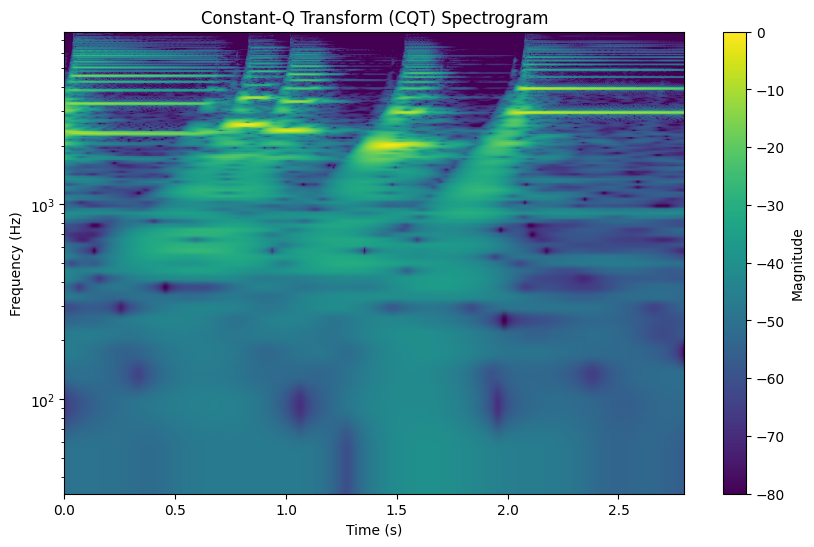

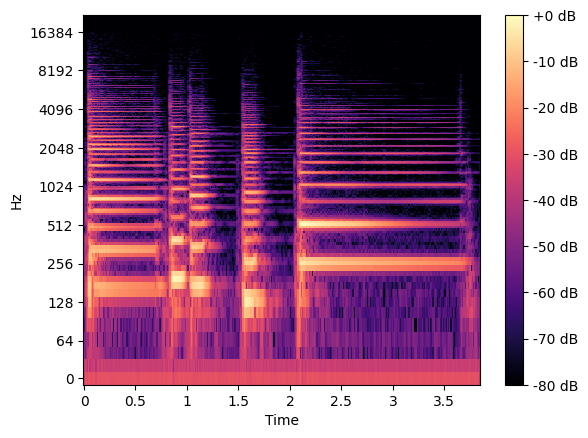

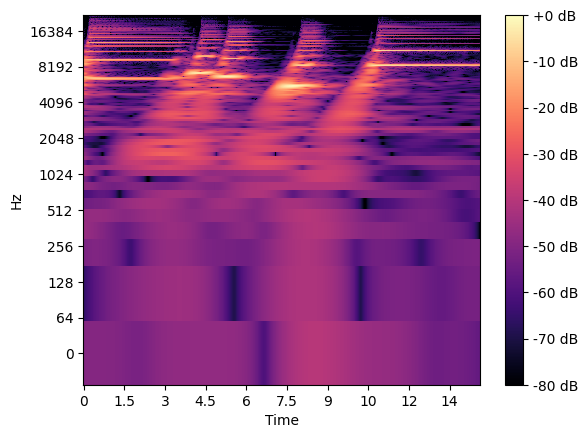

In [110]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import get_window
import librosa

def compute_cqt(signal, fs=16000, bins_per_octave=12, fmin=32.7, fmax=8000, window_type='hann'):
    """
    Compute the Constant-Q Transform (CQT) analytically.

    Parameters:
    - signal (numpy array): Input signal (1D array).
    - fs (int): Sampling rate in Hz.
    - bins_per_octave (int): Number of frequency bins per octave.
    - fmin (float): Minimum frequency (typically the lowest note in an instrument).
    - fmax (float): Maximum frequency.
    - window_type (str): Type of window function ('hann', 'hamming', etc.).
    
    Returns:
    - cqt_result (2D numpy array): CQT representation (freq_bins x time_frames).
    - fk (numpy array): Center frequencies of each bin.
    - times (numpy array): Time values for the CQT.
    """

    # Compute center frequencies for CQT bins (logarithmic scale)
    n_bins = int(np.log2(fmax / fmin) * bins_per_octave)
    fk = fmin * 2 ** (np.arange(n_bins) / bins_per_octave)

    # Window lengths for each frequency (adapting to constant Q)
    Q = 1 / (2 ** (1 / bins_per_octave) - 1)
    window_lengths = np.ceil(Q * fs / fk).astype(int)

    # Time frames based on the longest window
    hop_size = min(window_lengths) // 2  # Overlapping windows
    num_frames = (len(signal) - max(window_lengths)) // hop_size
    times = np.arange(num_frames) * hop_size / fs

    # Initialize CQT matrix
    cqt_result = np.zeros((n_bins, num_frames), dtype=np.complex128)

    # Compute CQT by applying windowed complex exponentials
    for i, (f, win_len) in enumerate(zip(fk, window_lengths)):
        # Create window function
        window = get_window(window_type, win_len)

        # Generate complex exponential (sinusoidal filter at frequency f)
        kernel = window * np.exp(-2j * np.pi * np.arange(win_len) * f / fs)

        # Convolve signal with the kernel (moving window dot product)
        for t in range(num_frames):
            frame = signal[t * hop_size:t * hop_size + win_len]
            if len(frame) == win_len:
                cqt_result[i, t] = np.sum(frame * kernel)

    return cqt_result, fk, times

# Example usage
signal, fs = librosa.load('piano.wav', sr=None)

# Compute CQT
cqt_result, fk, times = compute_cqt(signal, fs=fs, bins_per_octave=24, fmin=32.7, fmax=8000)

# Plot CQT magnitude response
plt.figure(figsize=(10, 6))
plt.imshow(librosa.amplitude_to_db(np.abs(cqt_result), ref=np.max), aspect='auto', origin='lower', extent=[times[0], times[-1], fk[0], fk[-1]])
plt.yscale("log")
plt.colorbar(label="Magnitude")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Constant-Q Transform (CQT) Spectrogram")
plt.show()

X = librosa.stft(signal, n_fft=2048, hop_length=512)
librosa.display.specshow(librosa.amplitude_to_db(np.abs(X), ref=np.max), sr=fs, x_axis='time', y_axis='log')
plt.colorbar(format='%+2.0f dB')
plt.show()                       

librosa.display.specshow(librosa.amplitude_to_db(np.abs(cqt_result), ref=np.max), sr=fs, x_axis='time', y_axis='log', fmin=32.7, fmax=8000)
plt.colorbar(format='%+2.0f dB')
plt.show()  

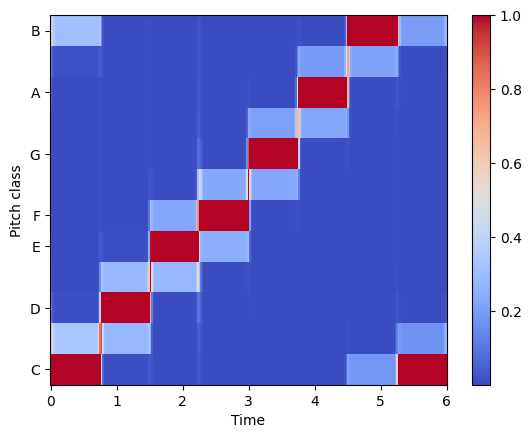

In [25]:
def compute_chroma_vector(audio_file, hop_length=512, n_fft=2048):
    """
    Compute and visualize the chroma feature of an audio file without using librosa.
    
    Parameters:
        audio_file (str): Path to the audio file.
        hop_length (int): Number of samples per frame for analysis.
        n_fft (int): Number of FFT points.
    """
    # Load audio
    y, sr = librosa.load(audio_file, sr=None)
    
    # Convert to mono if stereo
    if len(y.shape) > 1:
        y = np.mean(y, axis=1)
    
    # Compute STFT
    Zxx = librosa.stft(y, hop_length=hop_length, n_fft=n_fft)
    f = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
    t = librosa.frames_to_time(np.arange(Zxx.shape[1]), sr=sr, hop_length=hop_length)

    print(f)
    # Compute magnitude spectrogram
    magnitude = np.abs(Zxx)
    
    # Define chroma filter bank
    chroma_filter = np.zeros((12, len(f)))
    for i in range(len(f)):
        pitch_class = int(12 * np.log2(np.finfo(float).eps + f[i] / 440.0)) % 12
        chroma_filter[pitch_class, i] = 1
    
    # Compute chroma feature
    chroma = chroma_filter @ magnitude
    chroma = chroma / np.max(chroma, axis=0)  # Normalize
    
    # Plot chroma
    plt.figure(figsize=(10, 4))
    plt.imshow(chroma, aspect='auto', origin='lower', cmap='coolwarm', extent=[t.min(), t.max(), 0, 12])
    plt.colorbar()
    plt.title('Chroma Feature')
    plt.xlabel('Time')
    plt.ylabel('Pitch Class')
    plt.show()
    
    return chroma

# Example usage
# chroma_vector = compute_chroma_vector('chroma_example_signal.wav')
y, sr = librosa.load('chroma_example_signal.wav', sr=None)
chroma_vector = librosa.feature.chroma_stft(y=y, sr=sr, hop_length=512, n_fft=4096)
librosa.display.specshow(chroma_vector, y_axis='chroma', x_axis='time', cmap='coolwarm')
plt.colorbar()

Sample rate:  8000
Signal duration 3.0


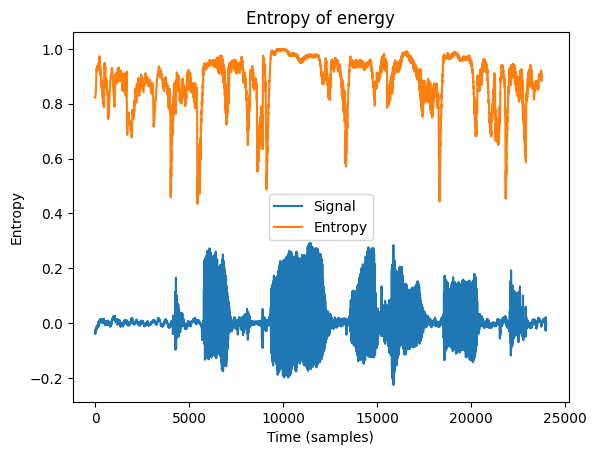

In [127]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fftpack import fft
import librosa
import IPython

signal, sample_rate = librosa.load('./content/sample_data/OSR_us_000_0010_8k.wav', sr=None)
signal = signal[:3*sample_rate]  # First 3 seconds

#signal, sample_rate = librosa.load('./content/sample_data/piano_classical.wav', sr=None)
# signal = signal[3*sample_rate:6*sample_rate]  # First 3 seconds

IPython.display.display(IPython.display.Audio(signal, rate=sample_rate))
print('Sample rate: ', sample_rate)
print('Signal duration', signal.shape[0]/sample_rate)

def enframe(signal, frame_size, hop_size):
    frames = []
    nframes = int(np.ceil((signal.shape[0] - frame_size)/hop_size)+1)
    padding_needed = (nframes-1)*hop_size + frame_size - signal.shape[0]
    signal_padded = np.concatenate((signal, np.zeros(padding_needed)))

    for i in range(nframes):
        start_index = i*hop_size
        end_index = start_index + frame_size
        frames.append(signal_padded[start_index:end_index])

    return np.array(frames)

# Entropy of energy
window_size = 256
hop_size = 1
frames = enframe(signal, window_size, hop_size)

entropy = []
for i in np.arange(frames.shape[0]):
    subframes = enframe(frames[i], 16, 16)
    subframe_energy = np.sum(subframes**2, axis=1)
    subframe_energy/=np.sum(frames[i]**2)

    entropy.append(subframe_energy)

entropy = np.array(entropy)
entropy = -np.sum(entropy*np.log2(entropy), axis=1)

plt.figure()
plt.plot(signal)
plt.plot(entropy/np.max(entropy))
plt.title('Entropy of energy')
plt.xlabel('Time (samples)')
plt.ylabel('Entropy')
plt.legend(['Signal', 'Entropy'])
plt.show()








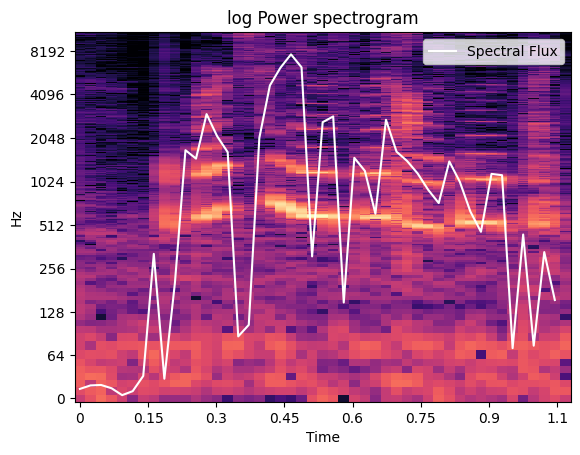

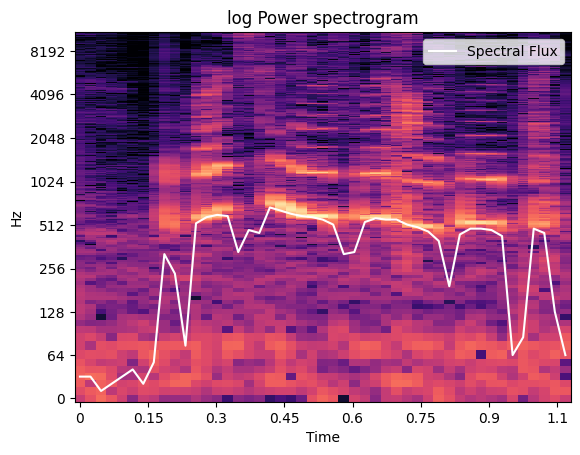

In [134]:

S = librosa.stft(signal, n_fft=2048, hop_length=512)
S = np.abs(S)

# CENTROID[t] = sum_k S[k, t] * freq[k] / (sum_j S[j, t])
# cent = librosa.feature.spectral_centroid(S=S)
# times = librosa.times_like(cent)
# fig, ax = plt.subplots()
# librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max),
#                          y_axis='log', x_axis='time', ax=ax)
# ax.plot(times, cent.T, label='Spectral centroid', color='w')
# ax.legend(loc='upper right')
# ax.set(title='log Power spectrogram')
# plt.show()


# Spectral Flux
spectral_flux = np.sum(np.diff(S, axis=1)**2, axis=0)
times = librosa.times_like(spectral_flux)
fig, ax = plt.subplots()
librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max),
                         y_axis='log', x_axis='time', ax=ax)
ax.plot(times, spectral_flux.T, label='Spectral Flux', color='w')
ax.legend(loc='upper right')
ax.set(title='log Power spectrogram')
plt.show()

# Spectral Rolloff
rolloff = librosa.feature.spectral_rolloff(S=S, roll_percent=0.1)
times = librosa.times_like(rolloff)
fig, ax = plt.subplots()
librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max),
                         y_axis='log', x_axis='time', ax=ax)
ax.plot(times, rolloff.T, label='Spectral Flux', color='w')
ax.legend(loc='upper right')
ax.set(title='log Power spectrogram')
plt.show()


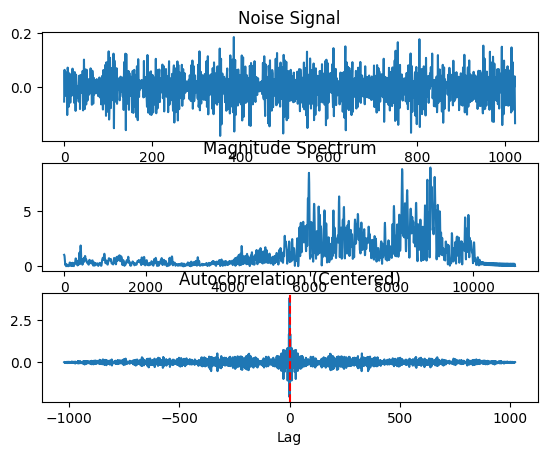

In [21]:
import librosa
import numpy as np
import IPython
from matplotlib import pyplot as plt

x, fs = librosa.load('voz.wav',sr=None)
IPython.display.display(IPython.display.Audio(x,rate=fs))

# Noise part
ruido=x[12600:12600+1024]
IPython.display.display(IPython.display.Audio(ruido,rate=fs))

corr = np.correlate(ruido, ruido, mode='full')
lags = np.arange(-len(ruido) + 1, len(ruido))  # Create centered x-axis

plt.subplot(3, 1, 1)
plt.plot(ruido)
plt.title("Noise Signal")
plt.subplot(3, 1, 2)
f = np.fft.rfftfreq(4096, 1/fs)
plt.plot(f,np.abs(np.fft.rfft(ruido, 4096)))
plt.title("Magnitude Spectrum")
plt.subplot(3,1,3)
plt.plot(lags, corr)  # Use centered lags
plt.title("Autocorrelation (Centered)")
plt.axvline(0, color='r', linestyle='--')  # Add vertical line at zero
plt.xlabel("Lag")
plt.show()

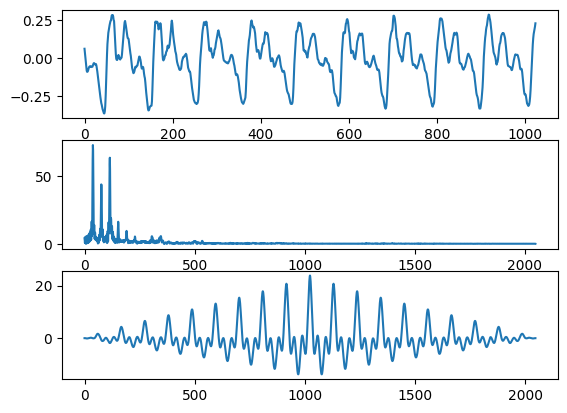

In [ ]:
# Voice part
s_sound=x[5000:5000+1024]
IPython.display.display(IPython.display.Audio(s_sound,rate=fs))

plt.subplot(3, 1, 1)
plt.plot(ruido)
plt.title("Noise Signal")
plt.subplot(3, 1, 2)
f = np.fft.rfftfreq(4096, 1/fs)
plt.plot(f,np.abs(np.fft.rfft(ruido, 4096)))
plt.title("Magnitude Spectrum")
plt.subplot(3,1,3)
plt.plot(lags, corr)  # Use centered lags
plt.title("Autocorrelation (Centered)")
plt.axvline(0, color='r', linestyle='--')  # Add vertical line at zero
plt.xlabel("Lag")
plt.show()